# Week2_ex2 — Phase-shifting transformer in a parallel path

Reproduces Example 3.13 and Problems 3.60–3.61 from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.): sign convention through the asymmetric Ybus, flows at 0° and +10°, and the loss sweeps over phase angle and tap. Problem 3.60 uses the resistances stored in the case file (line 0.03 pu, transformer 0.01 pu), which differ from the problem statement.

![PowerWorld one-line](Images/Week2_ex2_result_image.png)

In [1]:
# 1. Case data and per-unit conversion
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandapower as pp
from scipy.optimize import minimize_scalar

S_BASE = 500.0               # MVA, Simulator Options > Power Flow Solution > General
V_KV = 345.0
Z_BASE = V_KV**2 / S_BASE    # ohm
X_LINE, X_PST = 0.20, 0.25   # pu on the 500 MVA base
R_LINE_360, R_PST_360 = 0.03, 0.01
TAP = 1.05                   # off-nominal ratio on the Load Bus side (PowerWorld From bus)
MVA_TOL = 0.5

pd.DataFrame({
    "Quantity": ["System base", "Z_base", "Line R / X", "PST R / X", "PST tap / phase", "MVA convergence tolerance"],
    "PowerWorld": ["500 MVA", "-", "0 (3.60: 0.03) / 0.20 pu", "0 (3.60: 0.01) / 0.25 pu",
                   "1.05 on Load Bus, 0 deg", "0.5 MVA"],
    "pandapower": ["sn_mva=500", f"{Z_BASE:.2f} ohm", "ohm_per_km = pu * Z_base, length 1 km",
                   "sn_mva=500, vk/vkr in percent", "hv_bus=Load Bus, tap_side='hv', shift_degree", "MW/Mvar tolerance"],
})

,Quantity,PowerWorld,pandapower
0,System base,500 MVA,sn_mva=500
1,Z_base,-,238.05 ohm
2,Line R / X,0 (3.60: 0.03) / 0.20 pu,"ohm_per_km = pu * Z_base, length 1 km"
3,PST R / X,0 (3.60: 0.01) / 0.25 pu,"sn_mva=500, vk/vkr in percent"
4,PST tap / phase,"1.05 on Load Bus, 0 deg","hv_bus=Load Bus, tap_side='hv', shift_degree"
5,MVA convergence tolerance,0.5 MVA,MW/Mvar tolerance


In [2]:
# 2. Network builder and result extraction
def build_case(shift_deg, tap_ratio=TAP, r_line=0.0, r_pst=0.0):
    net = pp.create_empty_network(f_hz=60, sn_mva=S_BASE)
    gen_bus = pp.create_bus(net, vn_kv=V_KV, name="Generator Bus")
    load_bus = pp.create_bus(net, vn_kv=V_KV, name="Load Bus")
    pp.create_ext_grid(net, gen_bus, vm_pu=1.0, name="Slack")
    pp.create_load(net, load_bus, p_mw=500.0, q_mvar=100.0, name="Load")
    pp.create_line_from_parameters(net, gen_bus, load_bus, length_km=1.0, r_ohm_per_km=r_line * Z_BASE,
                                   x_ohm_per_km=X_LINE * Z_BASE, c_nf_per_km=0.0, max_i_ka=10.0, name="L2")
    # Both windings are 345 kV, so which bus is called "hv" is a free choice -- and it flips the sign
    # of the phase shift. hv_bus = Load Bus matches PowerWorld's From bus.
    # An "Ideal" changer refuses tap_step_percent and tap_step_degree together, so the ratio goes
    # through a "Ratio" tap and the angle through shift_degree.
    pp.create_transformer_from_parameters(
        net, hv_bus=load_bus, lv_bus=gen_bus, sn_mva=S_BASE, vn_hv_kv=V_KV, vn_lv_kv=V_KV,
        vk_percent=100 * np.hypot(r_pst, X_PST), vkr_percent=100 * r_pst, pfe_kw=0.0, i0_percent=0.0,
        shift_degree=shift_deg, tap_side="hv", tap_neutral=0, tap_min=-16, tap_max=16,
        tap_step_percent=(tap_ratio - 1) * 100, tap_pos=1, tap_changer_type="Ratio", name="PST")
    pp.runpp(net, numba=False)
    return net


def flows(net):
    line, pst, slack = net.res_line.iloc[0], net.res_trafo.iloc[0], net.res_ext_grid.iloc[0]
    return {
        "Load Bus voltage [kV]": net.res_bus.vm_pu.iat[1] * V_KV,
        "Slack P [MW]": slack.p_mw, "Slack Q [Mvar]": slack.q_mvar,
        "Line sending P [MW]": line.p_from_mw, "Line sending Q [Mvar]": line.q_from_mvar,
        "Line receiving P [MW]": -line.p_to_mw, "Line receiving Q [Mvar]": -line.q_to_mvar,
        "PST sending P [MW]": pst.p_lv_mw, "PST sending Q [Mvar]": pst.q_lv_mvar,
        "PST receiving P [MW]": -pst.p_hv_mw, "PST receiving Q [Mvar]": -pst.q_hv_mvar,
        "PST MW at From bus [MW]": pst.p_hv_mw,
        "Total P loss [MW]": net.res_line.pl_mw.sum() + net.res_trafo.pl_mw.sum(),
        "Total Q loss [Mvar]": net.res_line.ql_mvar.sum() + net.res_trafo.ql_mvar.sum(),
    }

In [3]:
# 3. Ybus at +3 deg against PowerWorld
def compare(rows):
    """Build a PowerWorld vs pandapower table and fail loudly on any miss."""
    df = pd.DataFrame(rows, columns=["Case", "Quantity", "PowerWorld", "pandapower", "Tolerance", "Source"])
    df["Abs error"] = (df["pandapower"] - df["PowerWorld"]).abs()
    bad = df[df["Abs error"] > df["Tolerance"]]
    assert bad.empty, bad
    return df.round({"pandapower": 5, "Abs error": 5})


# Example 3.13 at +3 deg (tap 1.05 kept), Solution Details > YBus, two decimals shown
ybus = build_case(3.0)._ppc["internal"]["Ybus"].toarray()
pw_ybus = {"Y11": -9.00j, "Y12": 0.20 + 8.80j, "Y21": -0.20 + 8.80j, "Y22": -8.63j}
rows = []
for key, pw in pw_ybus.items():
    i, j = int(key[1]) - 1, int(key[2]) - 1
    rows.append(["3.13, +3 deg", f"{key} real [pu]", pw.real, ybus[i, j].real, 5e-3, "Solution Details > YBus"])
    rows.append(["3.13, +3 deg", f"{key} imag [pu]", pw.imag, ybus[i, j].imag, 5e-3, "Solution Details > YBus"])

compare(rows)

,Case,Quantity,PowerWorld,pandapower,Tolerance,Source,Abs error
0,"3.13, +3 deg",Y11 real [pu],-0.00,0.00000,0.005,Solution Details > YBus,0.00000
1,"3.13, +3 deg",Y11 imag [pu],-9.00,-9.00000,0.005,Solution Details > YBus,0.00000
2,"3.13, +3 deg",Y12 real [pu],0.20,0.19938,0.005,Solution Details > YBus,0.00062
3,"3.13, +3 deg",Y12 imag [pu],8.80,8.80430,0.005,Solution Details > YBus,0.00430
4,"3.13, +3 deg",Y21 real [pu],-0.20,-0.19938,0.005,Solution Details > YBus,0.00062
5,"3.13, +3 deg",Y21 imag [pu],8.80,8.80430,0.005,Solution Details > YBus,0.00430
6,"3.13, +3 deg",Y22 real [pu],-0.00,0.00000,0.005,Solution Details > YBus,0.00000
7,"3.13, +3 deg",Y22 imag [pu],-8.63,-8.62812,0.005,Solution Details > YBus,0.00188


In [4]:
# 4. Example 3.13 flows at 0 and +10 deg
# PowerWorld values read once from PowerWorld Simulator (Run Mode, one-line and Model Explorer)
pw_313 = {
    0.0: {"Load Bus voltage [kV]": (341.86, 5e-3), "Slack P [MW]": (500.00, MVA_TOL), "Slack Q [Mvar]": (164.01, MVA_TOL),
          "Line sending P [MW]": (283.8, MVA_TOL), "Line sending Q [Mvar]": (39.0, MVA_TOL),
          "Line receiving P [MW]": (283.8, MVA_TOL), "Line receiving Q [Mvar]": (6.2, MVA_TOL),
          "PST sending P [MW]": (216.2, MVA_TOL), "PST sending Q [Mvar]": (125.0, MVA_TOL),
          "PST receiving P [MW]": (216.2, MVA_TOL), "PST receiving Q [Mvar]": (93.8, MVA_TOL),
          "PST MW at From bus [MW]": (-216.21599, MVA_TOL)},
    10.0: {"Load Bus voltage [kV]": (340.49, 5e-3), "Slack P [MW]": (500.0, MVA_TOL), "Slack Q [Mvar]": (198.0, MVA_TOL),
           "Line sending P [MW]": (99.3, MVA_TOL), "Line sending Q [Mvar]": (34.7, MVA_TOL),
           "Line receiving P [MW]": (99.3, MVA_TOL), "Line receiving Q [Mvar]": (30.3, MVA_TOL),
           "PST sending P [MW]": (400.7, MVA_TOL), "PST sending Q [Mvar]": (163.4, MVA_TOL),
           "PST receiving P [MW]": (400.7, MVA_TOL), "PST receiving Q [Mvar]": (69.7, MVA_TOL),
           "PST MW at From bus [MW]": (-400.69468, MVA_TOL)},
}
rows = []
for shift, pw in pw_313.items():
    pp_vals = flows(build_case(shift))
    for qty, (val, tol) in pw.items():
        src = "Transformer Controls, Reg Value" if "From bus" in qty else "One-line / Generators"
        rows.append([f"3.13, {shift:+.0f} deg", qty, val, pp_vals[qty], tol, src])

compare(rows)

,Case,Quantity,PowerWorld,pandapower,Tolerance,Source,Abs error
0,"3.13, +0 deg",Load Bus voltage [kV],341.86000,341.86424,0.005,One-line / Generators,0.00424
1,"3.13, +0 deg",Slack P [MW],500.00000,500.00000,0.500,One-line / Generators,0.00000
2,"3.13, +0 deg",Slack Q [Mvar],164.01000,164.00688,0.500,One-line / Generators,0.00312
3,"3.13, +0 deg",Line sending P [MW],283.80000,283.78378,0.500,One-line / Generators,0.01622
4,"3.13, +0 deg",Line sending Q [Mvar],39.00000,39.03093,0.500,One-line / Generators,0.03093
5,"3.13, +0 deg",Line receiving P [MW],283.80000,283.78378,0.500,One-line / Generators,0.01622
6,"3.13, +0 deg",Line receiving Q [Mvar],6.20000,6.20827,0.500,One-line / Generators,0.00827
7,"3.13, +0 deg",PST sending P [MW],216.20000,216.21622,0.500,One-line / Generators,0.01622
8,"3.13, +0 deg",PST sending Q [Mvar],125.00000,124.97595,0.500,One-line / Generators,0.02405
9,"3.13, +0 deg",PST receiving P [MW],216.20000,216.21622,0.500,One-line / Generators,0.01622


In [5]:
# 5. Problem 3.60 at 0 deg with resistance
pw_360 = {"Load Bus voltage [kV]": (337.57, 5e-3), "Slack P [MW]": (506.23, MVA_TOL), "Slack Q [Mvar]": (167.04, MVA_TOL),
          "Line sending P [MW]": (285.9, MVA_TOL), "Line sending Q [Mvar]": (27.2, MVA_TOL),
          "Line receiving P [MW]": (281.0, MVA_TOL), "Line receiving Q [Mvar]": (-5.8, MVA_TOL),
          "PST sending P [MW]": (220.3, MVA_TOL), "PST sending Q [Mvar]": (139.8, MVA_TOL),
          "PST receiving P [MW]": (219.0, MVA_TOL), "PST receiving Q [Mvar]": (105.8, MVA_TOL),
          "PST MW at From bus [MW]": (-218.95641, MVA_TOL),
          "Total P loss [MW]": (6.311, MVA_TOL), "Total Q loss [Mvar]": (67.040, MVA_TOL)}
# The one-line prints absolute values; the line's receiving-end Q is -5.8 Mvar
# (27.2 + 5.8 = 33.0 Mvar = I^2 X of the line).
pp_vals = flows(build_case(0.0, r_line=R_LINE_360, r_pst=R_PST_360))
rows = [["3.60, 0 deg", qty, val, pp_vals[qty], tol, "One-line / Generators"] for qty, (val, tol) in pw_360.items()]

compare(rows)

,Case,Quantity,PowerWorld,pandapower,Tolerance,Source,Abs error
0,"3.60, 0 deg",Load Bus voltage [kV],337.57000,337.57316,0.005,One-line / Generators,0.00316
1,"3.60, 0 deg",Slack P [MW],506.23000,506.31300,0.500,One-line / Generators,0.08300
2,"3.60, 0 deg",Slack Q [Mvar],167.04000,167.06128,0.500,One-line / Generators,0.02128
3,"3.60, 0 deg",Line sending P [MW],285.90000,285.95756,0.500,One-line / Generators,0.05756
4,"3.60, 0 deg",Line sending Q [Mvar],27.20000,27.21858,0.500,One-line / Generators,0.01858
5,"3.60, 0 deg",Line receiving P [MW],281.00000,281.00681,0.500,One-line / Generators,0.00681
6,"3.60, 0 deg",Line receiving Q [Mvar],-5.80000,-5.78645,0.500,One-line / Generators,0.01355
7,"3.60, 0 deg",PST sending P [MW],220.30000,220.35544,0.500,One-line / Generators,0.05544
8,"3.60, 0 deg",PST sending Q [Mvar],139.80000,139.84271,0.500,One-line / Generators,0.04271
9,"3.60, 0 deg",PST receiving P [MW],219.00000,218.99319,0.500,One-line / Generators,0.00681


In [6]:
# 6. Loss sweeps for Problems 3.60 and 3.61
def p_loss(shift_deg, tap_ratio=TAP):
    net = build_case(shift_deg, tap_ratio, r_line=R_LINE_360, r_pst=R_PST_360)
    return net.res_line.pl_mw.sum() + net.res_trafo.pl_mw.sum()


# Problem 3.60: tap fixed at 1.05, phase from -10 to +10 deg
angles = np.arange(-10.0, 10.0 + 1e-9, 0.5)
loss_vs_angle = np.array([p_loss(a) for a in angles])
best_angle = minimize_scalar(p_loss, bounds=(-10, 10), method="bounded", options={"xatol": 1e-4})

# Problem 3.61: phase fixed at 3.08 deg (value from the problem statement), tap from 0.90 to 1.10
taps = np.round(np.arange(0.90, 1.10 + 1e-9, 0.00625), 5)
loss_vs_tap = np.array([p_loss(3.08, t) for t in taps])
best_tap = minimize_scalar(lambda t: p_loss(3.08, t), bounds=(0.9, 1.1), method="bounded", options={"xatol": 1e-6})
best_step = taps[np.argmin(loss_vs_tap)]

pd.DataFrame({
    "Sweep": ["3.60 phase (tap 1.05)", "3.61 tap (phase 3.08 deg)", "3.61 tap, nearest LTC step"],
    "Loss-minimizing setting": [f"{best_angle.x:.2f} deg", f"{best_tap.x:.4f}", f"{best_step:.5f}"],
    "Minimum P loss [MW]": [best_angle.fun, best_tap.fun, loss_vs_tap.min()],
    "P loss at 0 deg / tap 1.00 [MW]": [p_loss(0.0), p_loss(3.08, 1.0), p_loss(3.08, 1.0)],
}).round(3)

,Sweep,Loss-minimizing setting,Minimum P loss [MW],P loss at 0 deg / tap 1.00 [MW]
0,3.60 phase (tap 1.05),8.14 deg,4.366,6.313
1,3.61 tap (phase 3.08 deg),1.0277,5.073,5.146
2,"3.61 tap, nearest LTC step",1.02500,5.074,5.146


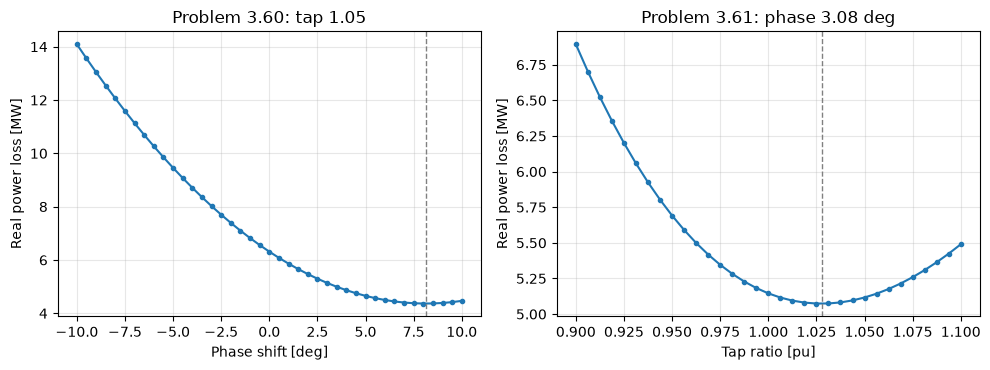

In [7]:
# 7. Plot the loss sweeps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(angles, loss_vs_angle, marker="o", ms=3)
ax1.axvline(best_angle.x, ls="--", lw=1, color="gray")
ax1.set(xlabel="Phase shift [deg]", ylabel="Real power loss [MW]", title="Problem 3.60: tap 1.05")
ax2.plot(taps, loss_vs_tap, marker="o", ms=3)
ax2.axvline(best_tap.x, ls="--", lw=1, color="gray")
ax2.set(xlabel="Tap ratio [pu]", ylabel="Real power loss [MW]", title="Problem 3.61: phase 3.08 deg")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("Images/Week2_ex2_loss_sweeps.png", dpi=150, bbox_inches="tight")
plt.show()